# Ji et al. 2020 — Cutaneous SCC (10x)
## 01 · Preprocessing, integration, cycling-scoped developmental manifold

Malignant keratinocytes from 10 cSCC patients. This dataset carries a large proliferating compartment; per the branching protocol (Filbin 2018 precedent) the cycling lobe is scoped out so the developmental fork can resolve. Threshold, overdispersion, PCA and Harmony are derived on the data in hand.

In [1]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Ji2020_Skin-2  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Skin)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir]*4))                 # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                                # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)            # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Ji2020_Skin-2 | category: Skin


### Load malignant cells + carry publication cell-cycle / subtype calls
The 3CA loader normalizes UMI counts and `log1p`s. We attach Ji 2020's own cell-cycle phase and tumor-keratinocyte subtype annotations (`Cells.csv`) for the cycling scope and for annotation grounded in the source publication.

In [3]:
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
cells = pd.read_csv(os.path.join(pth_in, 'Cells.csv'), index_col=0)
for c in ['g1s_score','g2m_score','cell_cycle_phase','cell_subtype_level1','cell_subtype_level2','mp_top']:
    adata.obs[c] = cells.loc[adata.obs_names, c].values
for c in ['g1s_score','g2m_score']:
    adata.obs[c] = adata.obs[c].astype(float)
print('malignant raw:', adata.shape, '| X max %.2f (counts->normalize_total, log1p)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Ji2020_Skin
Done.
malignant raw: (10598, 32738) | X max 8.12 (counts->normalize_total, log1p)


### Sample threshold — read the count inflection
Sort per-sample malignant counts and take the largest multiplicative gap as the inflection. There is a clean **6.70×** jump (40 → 268); keep samples above it.

In [4]:
n = adata.obs['sample'].value_counts()
s = np.sort(n.values)
print('sorted per-sample counts:', s.tolist())
print('adjacent ratios:', np.round(s[1:]/s[:-1], 2).tolist())
keep = n.index[n >= 100]                       # inflection sits in the 40->268 (6.70x) gap
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept %d/%d samples (>=100) -> %d cells' % (len(keep), n.size, adata.n_obs))

sorted per-sample counts: [27, 40, 268, 640, 729, 1012, 1064, 1130, 1472, 4216]
adjacent ratios: [1.48, 6.7, 2.39, 1.14, 1.39, 1.05, 1.06, 1.3, 2.86]
kept 8/10 samples (>=100) -> 10531 cells


### Gene filter + overdispersed selection (scFates)

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1443 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1443


### PCA → Harmony integration on `sample`
`theta=10`: this is a 10x dataset (Kürten/Filbin precedent for strong integration). The branch structure below survives this strong integration, which is the test that it is biology rather than a per-patient archipelago (the Kürten Gate-1 lesson).

In [6]:
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=20)

### Neighbors → UMAP → Leiden (whole malignant manifold)

In [7]:
sc.pp.neighbors(adata, n_pcs=20, n_neighbors=30, use_rep='X_pca_harmony')
sc.tl.umap(adata, spread=1.3, random_state=SEED)
sc.tl.leiden(adata, resolution=1.0, random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs.cell_cycle_phase.isin(['G1/S','G2/M','Intermediate'])
from scipy.sparse.csgraph import connected_components
ncomp, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connected components:', ncomp, '| leiden clusters:', adata.obs.leiden.nunique())

kNN connected components: 1 | leiden clusters: 14


### Gate 1 (mixing + continuity) — judged on the embedding
Samples intermix across the manifold (one connected kNN component); no per-patient islands. **Gate 1 GO.**

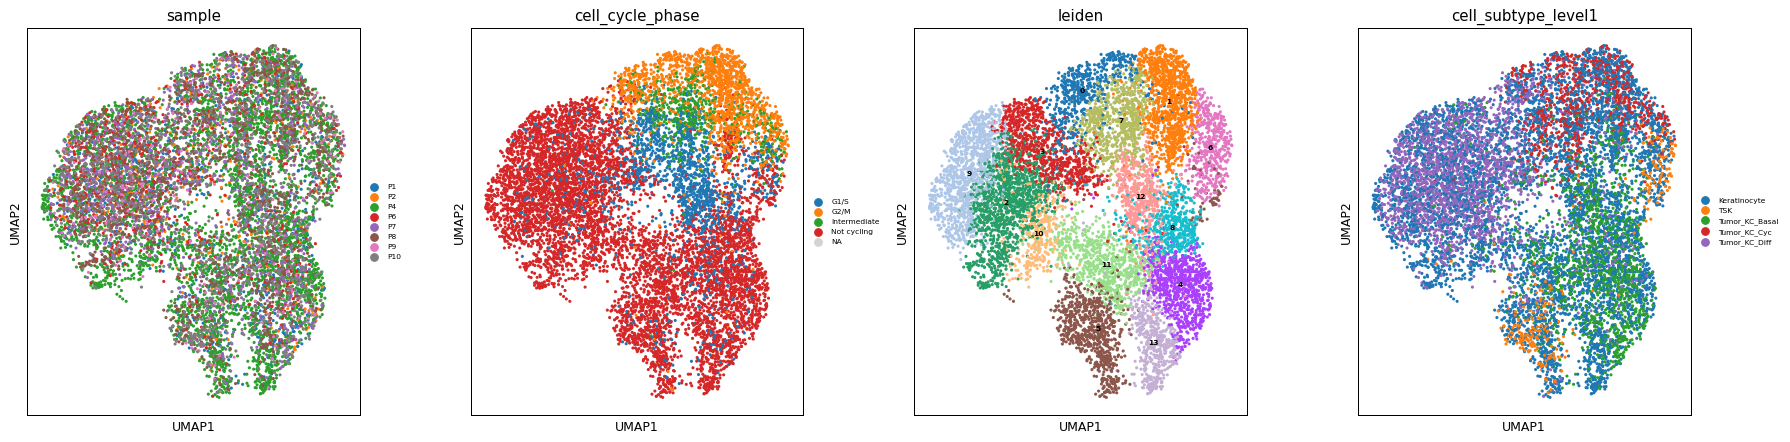

In [8]:
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, c in zip(axs, ['sample','cell_cycle_phase','leiden','cell_subtype_level1']):
    sc.pl.umap(adata, color=c, ax=ax, show=False, size=25,
               legend_loc='on data' if c=='leiden' else 'right margin', legend_fontsize=6)
    ax.set_title(c)
plt.tight_layout(); plt.show()

### Scope out the cycling compartment
The proliferating cells form a coherent lobe (a separate cell-cycle axis, not a developmental state). Per-Leiden cycling fraction cleanly splits clusters into cycling (>50%) and developmental. Removing the cycling compartment lets the embryonic fork resolve (Filbin 2018 branching protocol).

In [9]:
cyc = adata.obs.groupby('leiden', observed=True)['cycling'].mean().sort_values(ascending=False)
print('per-leiden cycling fraction:'); print(cyc.round(3).to_string())
cyc_lobes = cyc.index[cyc > 0.5].tolist()
adata.obs['compartment'] = np.where(adata.obs.leiden.isin(cyc_lobes), 'Cycling', 'Developmental')
print('cycling clusters:', cyc_lobes, '|', adata.obs.compartment.value_counts().to_dict())
fork = adata[adata.obs.compartment == 'Developmental'].copy()
print('developmental fork:', fork.n_obs, 'cells (removed', adata.n_obs - fork.n_obs, 'cycling)')

per-leiden cycling fraction:
leiden
7     0.984
1     0.880
12    0.848
6     0.819
0     0.800
8     0.235
3     0.210
4     0.098
5     0.093
2     0.087
13    0.084
10    0.057
11    0.051
9     0.029
cycling clusters: ['7', '1', '12', '6', '0'] | {'Developmental': 7085, 'Cycling': 3446}
developmental fork: 7085 cells (removed 3446 cycling)


### Re-embed the developmental fork
Fresh neighbors + UMAP on the Harmony rep, restricted to the developmental compartment.

In [10]:
sc.pp.neighbors(fork, n_pcs=20, n_neighbors=30, use_rep='X_pca_harmony')
sc.tl.umap(fork, spread=1.3, random_state=SEED)

### Score embryonic modules on the fork + identify hub and arms
Score Gast / pSom / Crest with the union control pool. The hub (**Mixed**) is the Leiden cluster with the highest joint (min z-scored) Gast+pSom co-expression — the module-convergence zone. Remaining clusters are labelled Gast- or pSom-leaning by their Gast−pSom bias relative to the hub.

In [11]:
fd = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates().dropna()
      for f in sorted(glob.glob(os.path.join(FEAT, '*.csv')))}
gref = fd['union'][fd['union'].isin(fork.var_names)]
for src, s in fd.items():
    if src == 'union': continue
    g = s[s.isin(fork.var_names)]
    sc.tl.score_genes(fork, gene_list=g, score_name=src, ctrl_as_ref=False, gene_pool=gref, random_state=1234)
fork.obs['Gast'] = fork.obs.GSE162534; fork.obs['pSom'] = fork.obs.GSE229103; fork.obs['Crest'] = fork.obs.rRNAModifications
A = fork.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg==0]=1
for k in ['Gast','pSom','Crest']: fork.obs[k+'_sm'] = (A @ fork.obs[k].values) / deg
sc.tl.leiden(fork, resolution=0.4, random_state=SEED, key_added='lz', flavor='igraph', n_iterations=2, directed=False)
prof = fork.obs.groupby('lz', observed=True).agg(n=('lz','size'), Gast=('Gast','mean'), pSom=('pSom','mean'), Crest=('Crest','mean'))
prof['zG'] = (prof.Gast - fork.obs.Gast.mean())/fork.obs.Gast.std()
prof['zP'] = (prof.pSom - fork.obs.pSom.mean())/fork.obs.pSom.std()
prof['joint'] = prof[['zG','zP']].min(axis=1); prof['GmP'] = prof.Gast - prof.pSom
print(prof.round(3).to_string())
hub = prof.joint.idxmax()
lab = {hub: 'Mixed'}
for lz in prof.index:
    if lz == hub: continue
    lab[lz] = 'Gast_arm' if prof.loc[lz,'GmP'] > prof.loc[hub,'GmP'] else 'pSom_arm'
fork.obs['celltype'] = pd.Categorical(fork.obs.lz.map(lab))
print('HUB (Mixed) cluster =', hub, '|', fork.obs.celltype.value_counts().to_dict())

       n   Gast   pSom  Crest     zG     zP  joint    GmP
lz                                                       
0   1945 -0.027  0.026  0.026 -0.142 -0.335 -0.335 -0.052
1   1497 -0.036  0.065  0.012 -0.313  0.353 -0.313 -0.100
2   1513 -0.000  0.063  0.004  0.353  0.327  0.327 -0.063
3   2130 -0.014  0.035  0.026  0.099 -0.175 -0.175 -0.048
HUB (Mixed) cluster = 2 | {'Gast_arm': 4075, 'Mixed': 1513, 'pSom_arm': 1497}


### Annotated fork — hub + two arms
Gast-leaning arm (Diff-keratinocyte side), pSom-leaning arm (Basal/TSK side), Mixed convergence hub. Annotation combines data-derived module geography with Ji 2020's tumor-keratinocyte subtypes.

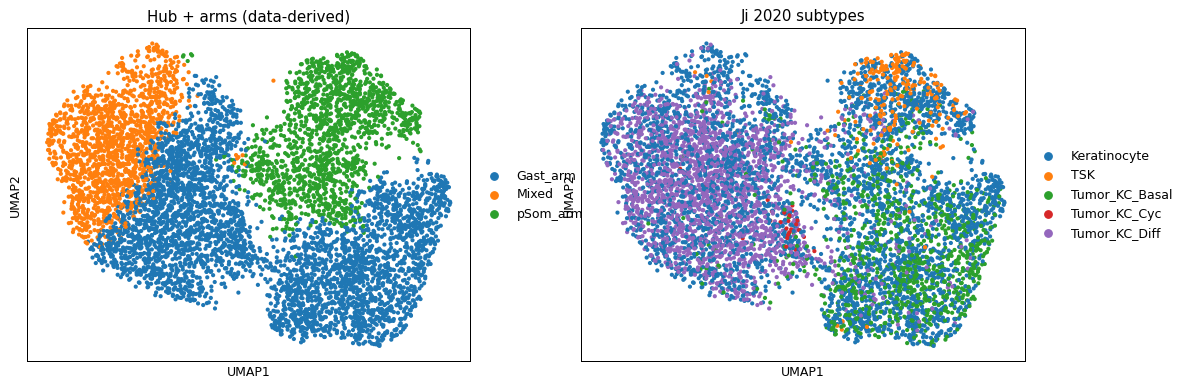

In [12]:
sc.pl.umap(fork, color=['celltype','cell_subtype_level1'], size=45,
           title=['Hub + arms (data-derived)','Ji 2020 subtypes']); plt.show()

### Save processed developmental manifold

In [13]:
fork.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', fork.shape)

saved processed.h5ad (7085, 21042)


### `samples.pdf` — sample integration on the developmental manifold

saved samples.pdf


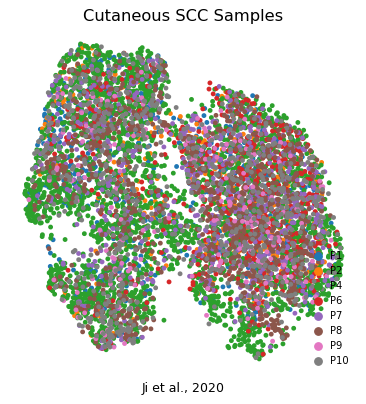

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(fork, color='sample', size=60, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='lower right', columnspacing=.5, handletextpad=.25, fontsize=8)
ax.set_title('Cutaneous SCC Samples', size=13)
ax.text(.5, -.05, 'Ji et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf')